# 03 — Feature engineering, model comparison, tuning and final model
Same validation scheme as notebook 02: 80/20 random hold-out (same `random_state`), the training part is
cleaned, the validation part is not; all preprocessing is fitted inside pipelines on the training part only.

In [1]:
import sys
sys.path.append("..")
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split

from src.data import FIG_DIR, RANDOM_STATE, ROOT, SUB_DIR, TARGET, clean_train, load_data, rmse
from src.features import TaxiFeatures
from src.models import LGB_QUICK, lgb_pipeline, linear_pipeline, rf_pipeline

train, test = load_data()
tr, va = train_test_split(train, test_size=0.2, random_state=RANDOM_STATE)
tr = clean_train(tr)
y_tr, y_va = np.log1p(tr[TARGET]), np.log1p(va[TARGET].to_numpy())
print(f"training part (cleaned): {len(tr):,}   validation part: {len(va):,}")

training part (cleaned): 1,164,447   validation part: 291,729


## 1. Feature engineering
Built in `src/features.py`, grouped so that each group's effect can be measured:

| group | features | why (from the EDA) |
|---|---|---|
| raw | vendor, passengers, 4 coordinates, store_and_fwd (0/1) | original columns |
| `datetime` | hour, minute of day, weekday, hour-of-week, month, day of year, weekend flag | traffic depends on time of day × day of week |
| `distance` | haversine and Manhattan distance, log distance, bearing, trip centre, airport flags (JFK/LGA/EWR within 2 km), outside-NYC flag | distance is the strongest driver of duration but is not a raw column |
| `pca` | pickup/dropoff coordinates rotated by PCA, and the Manhattan distance in the rotated system | Manhattan's street grid is tilted ~29°; after rotation the grid aligns with the axes, which helps axis-aligned tree splits |
| `clusters` | KMeans zone (50 clusters) of pickup and dropoff | neighbourhood-level effects (airports, Midtown congestion) |

PCA and KMeans are **learned** transformations, so they are fitted on the training fold only (inside the pipeline).

### 1.1 Effect of each group on the validation score
Fixed LightGBM parameters (`LGB_QUICK`: 400 trees, learning rate 0.1). Two experiments:
adding groups one by one, and removing one group at a time from the full set.

In [2]:
def score_groups(groups):
    t = time.time()
    pred = lgb_pipeline(groups=groups).fit(tr, y_tr).predict(va)
    return round(rmse(y_va, pred), 5), round(time.time() - t)

ablation = []
steps = [(), ("datetime",), ("datetime", "distance"), ("datetime", "distance", "pca"),
         ("datetime", "distance", "pca", "clusters")]
for g in steps:
    s, sec = score_groups(g)
    ablation.append({"experiment": "add", "feature groups": "raw + " + " + ".join(g) if g else "raw only",
                     "valid RMSLE": s, "seconds": sec})
    print(ablation[-1])
full_score = ablation[-1]["valid RMSLE"]
for drop in TaxiFeatures.ALL_GROUPS:
    g = tuple(x for x in TaxiFeatures.ALL_GROUPS if x != drop)
    s, sec = score_groups(g)
    ablation.append({"experiment": "remove", "feature groups": f"all − {drop}", "valid RMSLE": s, "seconds": sec})
    print(ablation[-1])
ablation = pd.DataFrame(ablation)
ablation["Δ vs all features"] = (ablation["valid RMSLE"] - full_score).round(5)
ablation.to_csv(ROOT / "reports" / "results_03_feature_ablation.csv", index=False)
ablation

{'experiment': 'add', 'feature groups': 'raw only', 'valid RMSLE': 0.46004, 'seconds': 18}


{'experiment': 'add', 'feature groups': 'raw + datetime', 'valid RMSLE': 0.41651, 'seconds': 24}


{'experiment': 'add', 'feature groups': 'raw + datetime + distance', 'valid RMSLE': 0.38576, 'seconds': 27}


{'experiment': 'add', 'feature groups': 'raw + datetime + distance + pca', 'valid RMSLE': 0.38501, 'seconds': 34}


{'experiment': 'add', 'feature groups': 'raw + datetime + distance + pca + clusters', 'valid RMSLE': 0.38463, 'seconds': 36}


{'experiment': 'remove', 'feature groups': 'all − datetime', 'valid RMSLE': 0.44232, 'seconds': 28}


{'experiment': 'remove', 'feature groups': 'all − distance', 'valid RMSLE': 0.39703, 'seconds': 28}


{'experiment': 'remove', 'feature groups': 'all − pca', 'valid RMSLE': 0.38486, 'seconds': 35}


{'experiment': 'remove', 'feature groups': 'all − clusters', 'valid RMSLE': 0.38501, 'seconds': 31}


,experiment,feature groups,valid RMSLE,seconds,Δ vs all features
0,add,raw only,0.46004,18,0.07541
1,add,raw + datetime,0.41651,24,0.03188
2,add,raw + datetime + distance,0.38576,27,0.00113
3,add,raw + datetime + distance + pca,0.38501,34,0.00038
4,add,raw + datetime + distance + pca + clusters,0.38463,36,0.00000
5,remove,all − datetime,0.44232,28,0.05769
6,remove,all − distance,0.39703,28,0.01240
7,remove,all − pca,0.38486,35,0.00023
8,remove,all − clusters,0.38501,31,0.00038


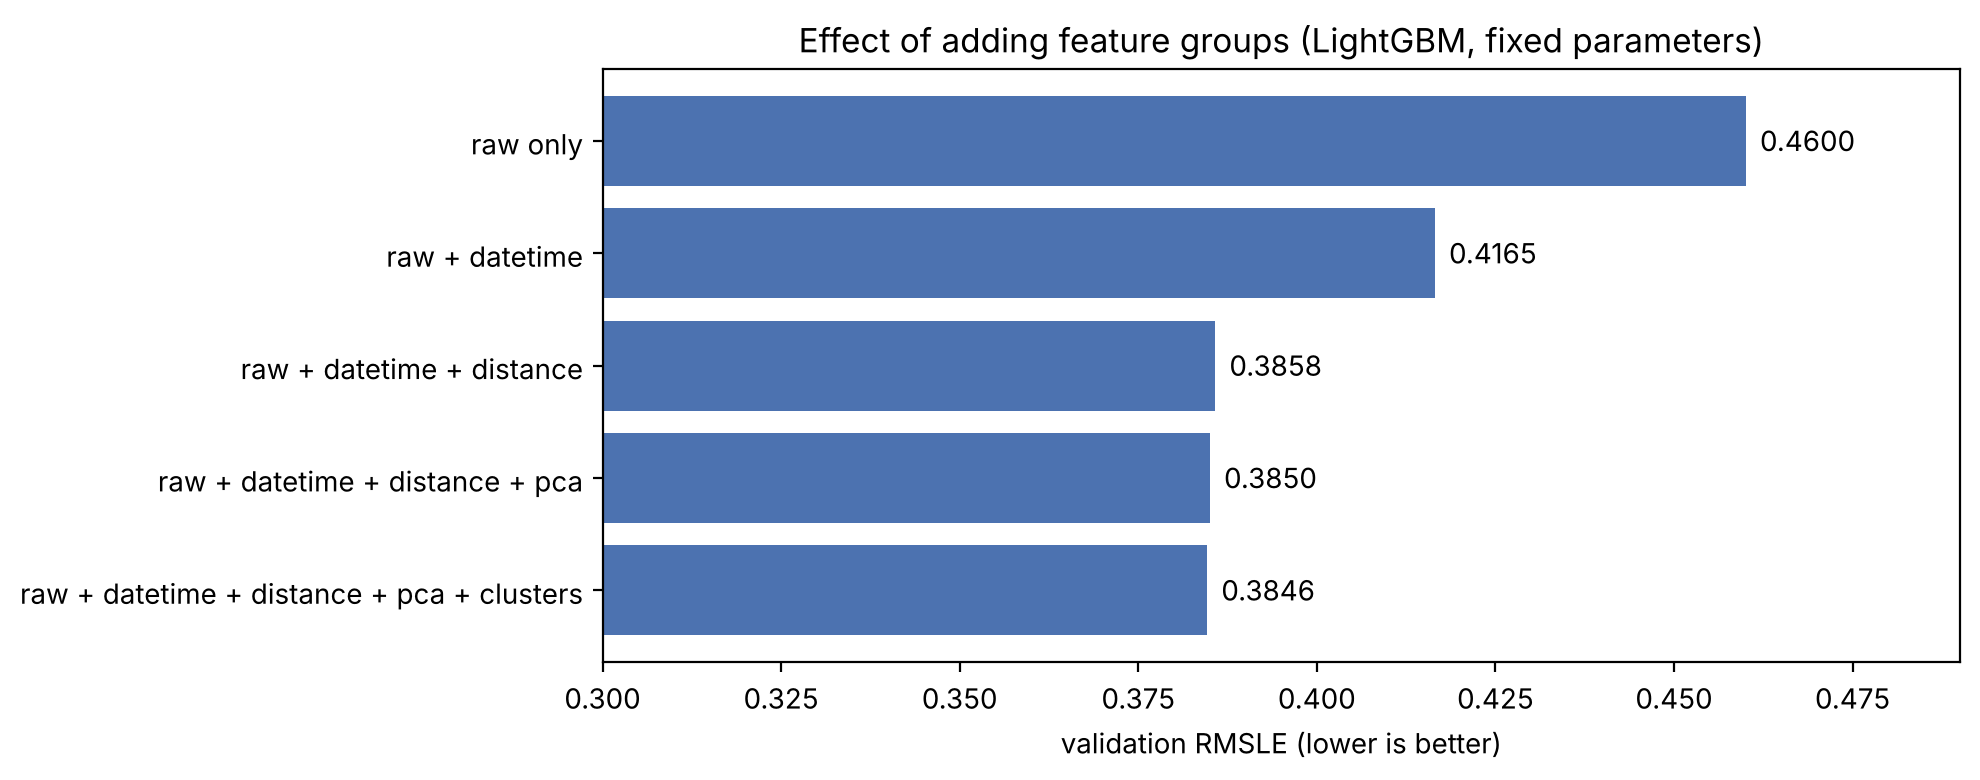

In [3]:
add = ablation[ablation.experiment == "add"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(add["feature groups"], add["valid RMSLE"], color="#4C72B0")
for i, v in enumerate(add["valid RMSLE"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center")
ax.set(xlabel="validation RMSLE (lower is better)", title="Effect of adding feature groups (LightGBM, fixed parameters)",
       xlim=(0.3, add["valid RMSLE"].max() + 0.03))
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_feature_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.**
* **Datetime features** give the largest gain: 0.460 → 0.417, and removing them from the full set costs
  +0.058. The time-of-day × weekday traffic pattern from the EDA is the main signal the raw columns lack.
* **Distance features** take the score to 0.386 (−0.031). Removing them from the full set costs only +0.012,
  because the PCA-rotated coordinates partly recover the distance.
* **PCA rotation** and **KMeans zones** each add a small but consistent gain (≈ −0.0004 to −0.0008).
  That is small compared with the first two groups, but it shows up both when adding and when removing them.

### 1.2 Feature importance and selection
LightGBM "gain" importance of the full model: how much each feature reduced the loss in total.

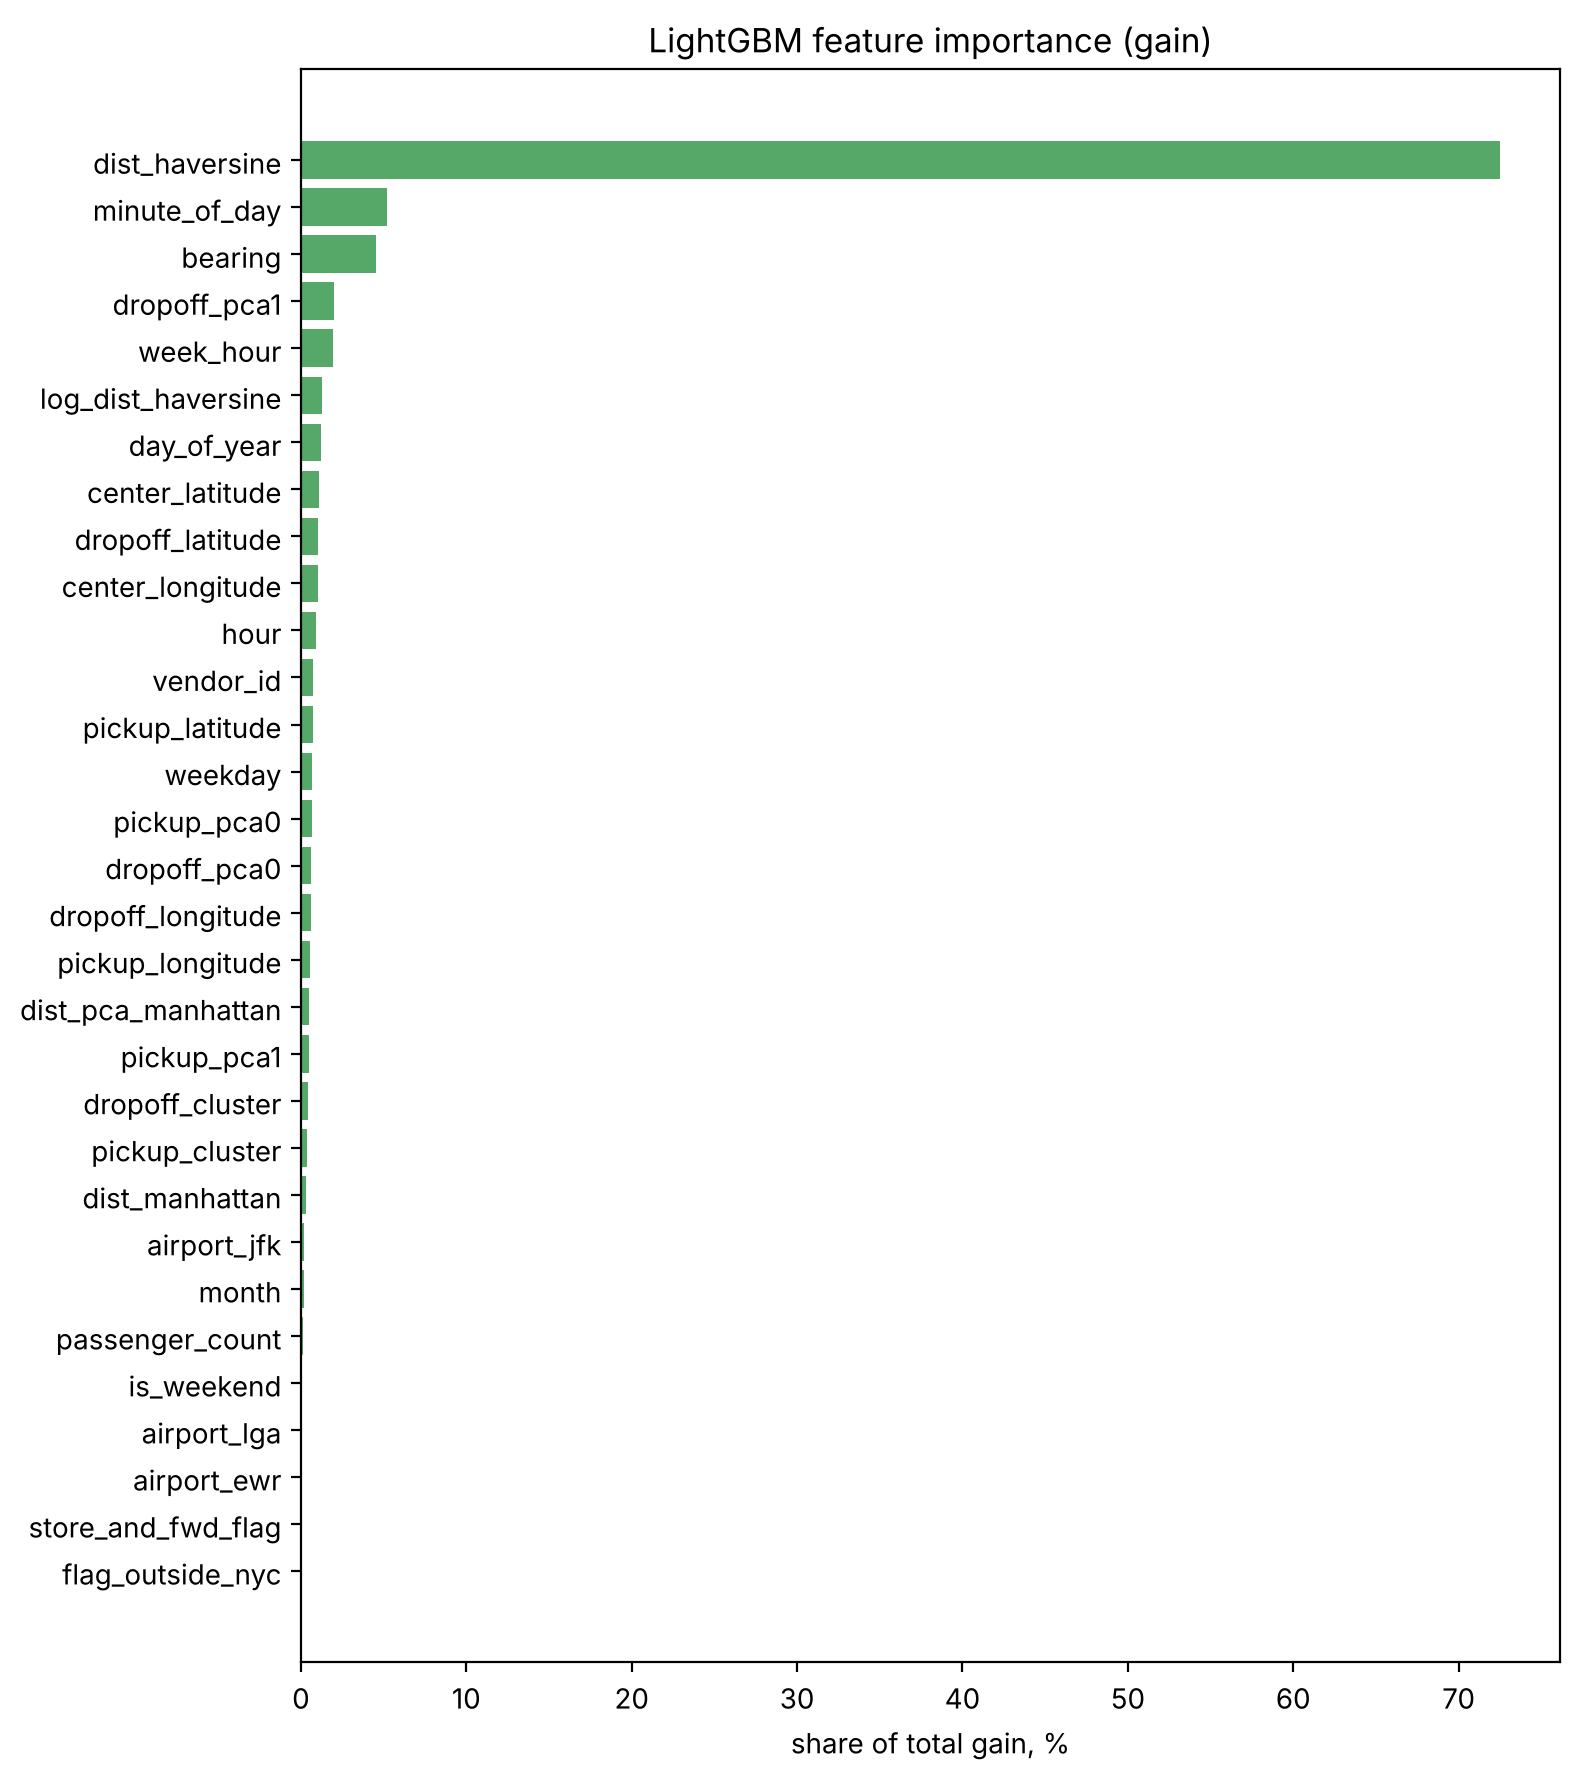

features with < 0.1% of the gain: ['flag_outside_nyc', 'store_and_fwd_flag', 'airport_ewr', 'airport_lga', 'is_weekend']


In [4]:
full_pipe = lgb_pipeline().fit(tr, y_tr)
names = full_pipe.named_steps["features"].transform(tr.head(5)).columns
imp = pd.Series(full_pipe.named_steps["model"].booster_.feature_importance("gain"), index=names)
imp = (imp / imp.sum() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(imp.index, imp.values, color="#55A868")
ax.set(xlabel="share of total gain, %", title="LightGBM feature importance (gain)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
low = imp[imp < 0.1].index.tolist()
print("features with < 0.1% of the gain:", low)

Selection check: do the low-importance features hurt? We drop them and re-score.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

drop_low = Pipeline([
    ("features", TaxiFeatures()),
    ("select", FunctionTransformer(lambda X: X.drop(columns=low))),
    ("model", lgb.LGBMRegressor(**LGB_QUICK)),
]).fit(tr, y_tr)
s_drop = rmse(y_va, drop_low.predict(va))
print(f"all features: {full_score:.5f}   without {len(low)} low-importance features: {s_drop:.5f}")

all features: 0.38463   without 5 low-importance features: 0.38455


Dropping the five weakest features (outside-NYC flag, store_and_fwd flag, EWR / LGA airport flags, weekend flag)
changes the score by less than 0.0001, which is noise. They carry almost no information beyond the other columns
(e.g. `is_weekend` duplicates `weekday`). We **keep all features**: removing them does not help, and the flags
remain useful for reading the model.

## 2. Three model families on the same validation
* **Ridge** (linear) — one-hot + scaling, all features. Regularisation strength `alpha` chosen on a
  3-fold CV inside the training part.
* **Random forest** — bagging of deep trees. sklearn's forest is slow on 1.2M rows with 2 CPU cores, so it is
  trained on a 300k-row sample; for a fair comparison LightGBM is also reported on the same sample.
* **LightGBM** — gradient boosting; tuned in section 3.

In [6]:
# The two baselines from Part 2, recomputed here so this part also runs on its own
from src.features import distance_features
d_tr = distance_features(tr)["dist_haversine"]
d_va = distance_features(va)["dist_haversine"]
_, edges = pd.qcut(d_tr, 20, retbins=True, duplicates="drop")
edges[0], edges[-1] = -np.inf, np.inf
bin_mean = y_tr.groupby(pd.cut(d_tr, edges), observed=False).mean()
pred_rule = pd.cut(d_va, edges).map(bin_mean).astype(float).to_numpy()
results = pd.DataFrame([
    {"model": "constant (geometric mean)", "valid RMSLE": round(rmse(y_va, np.full(len(va), y_tr.mean())), 5),
     "note": "trivial baseline"},
    {"model": "rule: mean by distance bin", "valid RMSLE": round(rmse(y_va, pred_rule), 5),
     "note": "20 quantile bins of haversine distance"},
])

# full LightGBM model from section 1.2 (re-fitted if this part was started below 1.2)
if "full_pipe" not in globals():
    full_pipe = lgb_pipeline().fit(tr, y_tr)

def add_result(name, pred, note=""):
    global results
    s = round(rmse(y_va, pred), 5)
    results = pd.concat([results, pd.DataFrame([{"model": name, "valid RMSLE": s, "note": note}])], ignore_index=True)
    print(f"{name:<45s} {s:.5f}")
    results.to_csv(ROOT / "reports" / "results_03_model_comparison.csv", index=False)   # saved after every model

### 2.1 Ridge: tuning alpha

In [7]:
sub300 = tr.sample(300_000, random_state=RANDOM_STATE)
cv = KFold(3, shuffle=True, random_state=RANDOM_STATE)
ridge_search = RandomizedSearchCV(
    linear_pipeline(), {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}, n_iter=6, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1,
).fit(sub300, np.log1p(sub300[TARGET]))
print(pd.DataFrame(ridge_search.cv_results_)[["param_model__alpha", "mean_test_score"]].assign(
    cv_RMSLE=lambda d: -d.mean_test_score).drop(columns="mean_test_score"))
best_alpha = ridge_search.best_params_["model__alpha"]
ridge = linear_pipeline(alpha=best_alpha).fit(tr, y_tr)
add_result("Ridge (tuned alpha)", ridge.predict(va), f"alpha={best_alpha}, full training part")

   param_model__alpha  cv_RMSLE
0                0.01  0.420534
1                0.10  0.420532
2                1.00  0.420533
3               10.00  0.420550
4              100.00  0.420867
5             1000.00  0.423657


Ridge (tuned alpha)                           0.46605


The regularisation strength barely matters (CV RMSLE 0.4205 for alpha 0.01–10): with ~1M rows and ~200 columns
Ridge is not over-fitting, it is **under-fitting**. A linear model cannot represent interactions such as
"distance × time of day" or "airport × hour", which is why it stays far behind the tree models.

Note that the CV score (0.42) is better than the hold-out score (0.47): the CV folds come from the *cleaned*
training part, while the hold-out still contains the unpredictable 24 h trips (notebook 02). The same gap appears
for LightGBM below. CV is therefore used only to **rank** candidates; the hold-out gives the realistic estimate.

### 2.2 Random forest vs LightGBM on the same 300k sample

In [8]:
t = time.time()
rf = rf_pipeline(n_estimators=100, min_samples_leaf=10, max_features=0.5).fit(sub300, np.log1p(sub300[TARGET]))
add_result("Random forest (300k sample)", rf.predict(va), f"100 trees, leaf>=10, {time.time() - t:.0f}s")
t = time.time()
lgb300 = lgb_pipeline().fit(sub300, np.log1p(sub300[TARGET]))
add_result("LightGBM untuned (300k sample)", lgb300.predict(va), f"400 trees, {time.time() - t:.0f}s")
add_result("LightGBM untuned (full training part)", full_pipe.predict(va), "400 trees")

Random forest (300k sample)                   0.40396


LightGBM untuned (300k sample)                0.39289


LightGBM untuned (full training part)         0.38463


On the same 300k sample, LightGBM (0.393) beats the random forest (0.404) and is ~10× faster. Gradient boosting
fits the residuals of earlier trees, so it captures fine interactions better than averaging independent deep
trees. Using all 1.16M rows instead of 300k improves LightGBM by another 0.008: more data helps.

## 3. Hyper-parameter tuning of LightGBM
**Method:** random search (25 candidates) over the parameters that control tree complexity and
regularisation, scored by 3-fold CV RMSLE on a 300k sample of the training part (the hold-out is not
touched, so its score stays an honest estimate). The learning rate is fixed at 0.1 during the search to keep it
fast; afterwards the best configuration is re-trained with a lower learning rate (0.03) and the number of trees is
chosen by early stopping on a 10% slice *of the training part*.

In [9]:
param_space = {
    "model__num_leaves": randint(31, 512),
    "model__min_child_samples": randint(10, 300),
    "model__colsample_bytree": uniform(0.4, 0.6),
    "model__subsample": uniform(0.6, 0.4),
    "model__reg_lambda": loguniform(1e-3, 100),
    "model__max_bin": [255, 511],
}
t = time.time()
search = RandomizedSearchCV(
    lgb_pipeline(params={**LGB_QUICK, "n_estimators": 300}), param_space, n_iter=25, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1, refit=False,
).fit(sub300, np.log1p(sub300[TARGET]))
print(f"search took {time.time() - t:.0f}s")
cv_res = (pd.DataFrame(search.cv_results_)
          .assign(cv_RMSLE=lambda d: (-d.mean_test_score).round(5), cv_std=lambda d: d.std_test_score.round(5))
          .sort_values("cv_RMSLE"))
cv_res.to_csv(ROOT / "reports" / "results_03_lgb_search.csv", index=False)
cv_res[[c for c in cv_res if c.startswith("param_")] + ["cv_RMSLE", "cv_std"]].head(10)

search took 981s


,param_model__colsample_bytree,param_model__max_bin,param_model__min_child_samples,param_model__num_leaves,param_model__reg_lambda,param_model__subsample,cv_RMSLE,cv_std
4,0.575287,511,280,220,0.002838,0.847354,0.33911,0.00239
23,0.531064,511,295,476,0.497406,0.922976,0.33941,0.00252
7,0.538536,511,273,461,0.007359,0.756424,0.34015,0.00253
2,0.412351,511,201,474,0.008261,0.721697,0.34025,0.00257
5,0.629477,511,140,337,2.520796,0.780200,0.34045,0.00296
20,0.737965,511,231,437,1.052172,0.815936,0.34046,0.00239
10,0.758740,511,280,486,0.711574,0.808334,0.34049,0.00249
12,0.614052,511,197,410,0.023988,0.718509,0.34057,0.00234
16,0.598539,511,71,246,2.136052,0.836519,0.34115,0.00300
11,0.976703,255,217,267,0.022738,0.931495,0.34145,0.00299


**Search result.** The best candidates all have **large trees** (`num_leaves` 220–480) with **large leaves**
(`min_child_samples` ≈ 200–300) and use ~50–60% of the columns per tree. Many leaves capture interactions
such as zone × time; large leaves and column subsampling keep this from over-fitting.
The top candidates are within ~1 CV standard deviation (≈ 0.0025) of each other, so the exact values matter
less than the general region.

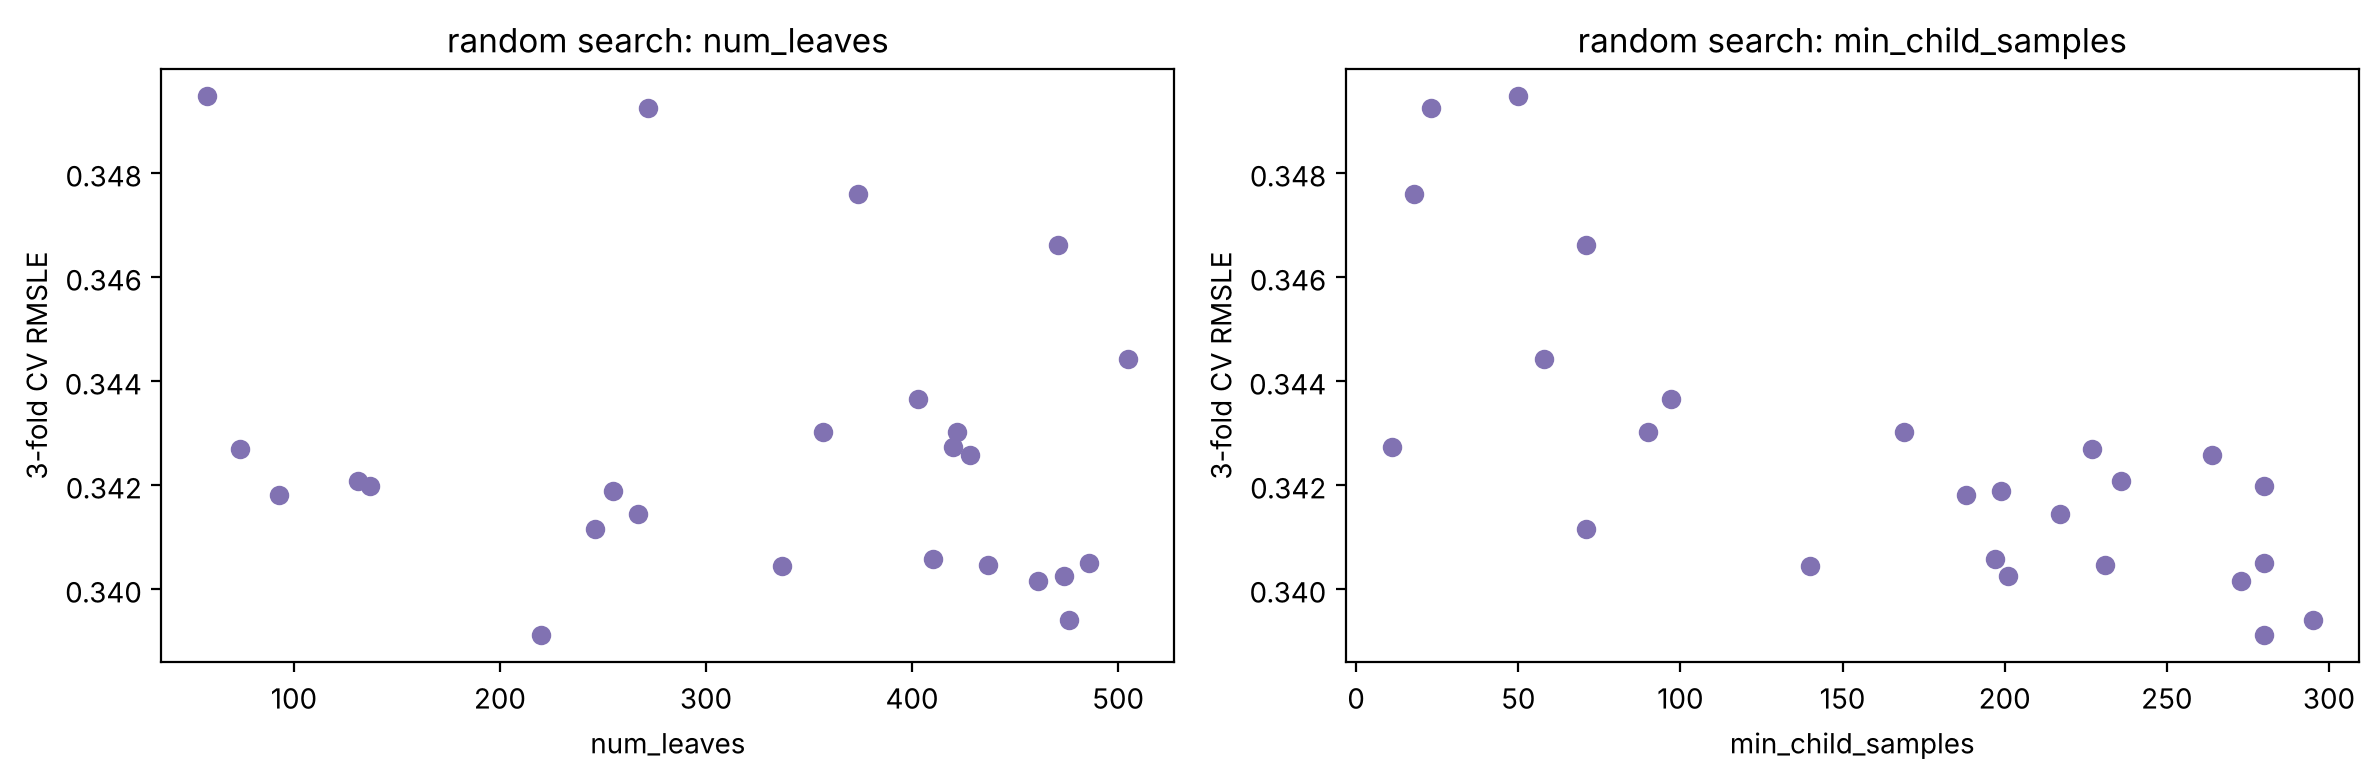

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, p in zip(axes, ["param_model__num_leaves", "param_model__min_child_samples"]):
    ax.scatter(cv_res[p].astype(float), cv_res["cv_RMSLE"], color="#8172B2")
    ax.set(xlabel=p.replace("param_model__", ""), ylabel="3-fold CV RMSLE", title=f"random search: {p.replace('param_model__', '')}")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
best["subsample_freq"] = 1
print("best parameters:", best)
tuned_params = {**LGB_QUICK, **best, "learning_rate": 0.03, "n_estimators": 5000}

# early stopping on a slice of the TRAINING part (the hold-out stays unseen)
fit_part, es_part = train_test_split(tr, test_size=0.1, random_state=RANDOM_STATE)
feats = TaxiFeatures().fit(fit_part)
X_fit, X_es, X_va = feats.transform(fit_part), feats.transform(es_part), feats.transform(va)
t = time.time()
tuned = lgb.LGBMRegressor(**tuned_params).fit(
    X_fit, np.log1p(fit_part[TARGET]), eval_set=[(X_es, np.log1p(es_part[TARGET]))],
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(500)])
best_iter = tuned.best_iteration_
import json
(ROOT / "reports" / "tuned_lightgbm.json").write_text(json.dumps(
    {"params": {k: (v.item() if hasattr(v, "item") else v) for k, v in tuned_params.items()}, "best_iter": int(best_iter)}, indent=2))
add_result("LightGBM tuned (full training part)", tuned.predict(X_va, num_iteration=best_iter),
           f"lr {tuned_params['learning_rate']}, {best_iter} trees, {time.time() - t:.0f}s")

best parameters: {'colsample_bytree': np.float64(0.5752867891211308), 'max_bin': 511, 'min_child_samples': 280, 'num_leaves': 220, 'reg_lambda': np.float64(0.0028381292701126727), 'subsample': np.float64(0.8473544037332349), 'subsample_freq': 1}


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[500]	valid_0's l2: 0.110516


[1000]	valid_0's l2: 0.107273


[1500]	valid_0's l2: 0.106064


[2000]	valid_0's l2: 0.105329


[2500]	valid_0's l2: 0.105037


[3000]	valid_0's l2: 0.104832


LightGBM tuned (full training part)           0.37290


Tuning + lower learning rate + early stopping: **0.3846 → 0.3729** on the hold-out (−0.012), the largest single
improvement after feature engineering.

## 4. Comparison of all models (same validation set)

In [12]:
if "results" not in globals():      # session was reset: read the scores saved by add_result
    results = pd.read_csv(ROOT / "reports" / "results_03_model_comparison.csv")
results = results.sort_values("valid RMSLE", ascending=False).reset_index(drop=True)
results.to_csv(ROOT / "reports" / "results_03_model_comparison.csv", index=False)
results

,model,valid RMSLE,note
0,constant (geometric mean),0.79665,trivial baseline
1,rule: mean by distance bin,0.51379,20 quantile bins of haversine distance
2,Ridge (tuned alpha),0.46605,"alpha=0.1, full training part"
3,Random forest (300k sample),0.40396,"100 trees, leaf>=10, 138s"
4,LightGBM untuned (300k sample),0.39289,"400 trees, 14s"
5,LightGBM untuned (full training part),0.38463,400 trees
6,LightGBM tuned (full training part),0.37290,"lr 0.03, 3064 trees, 352s"


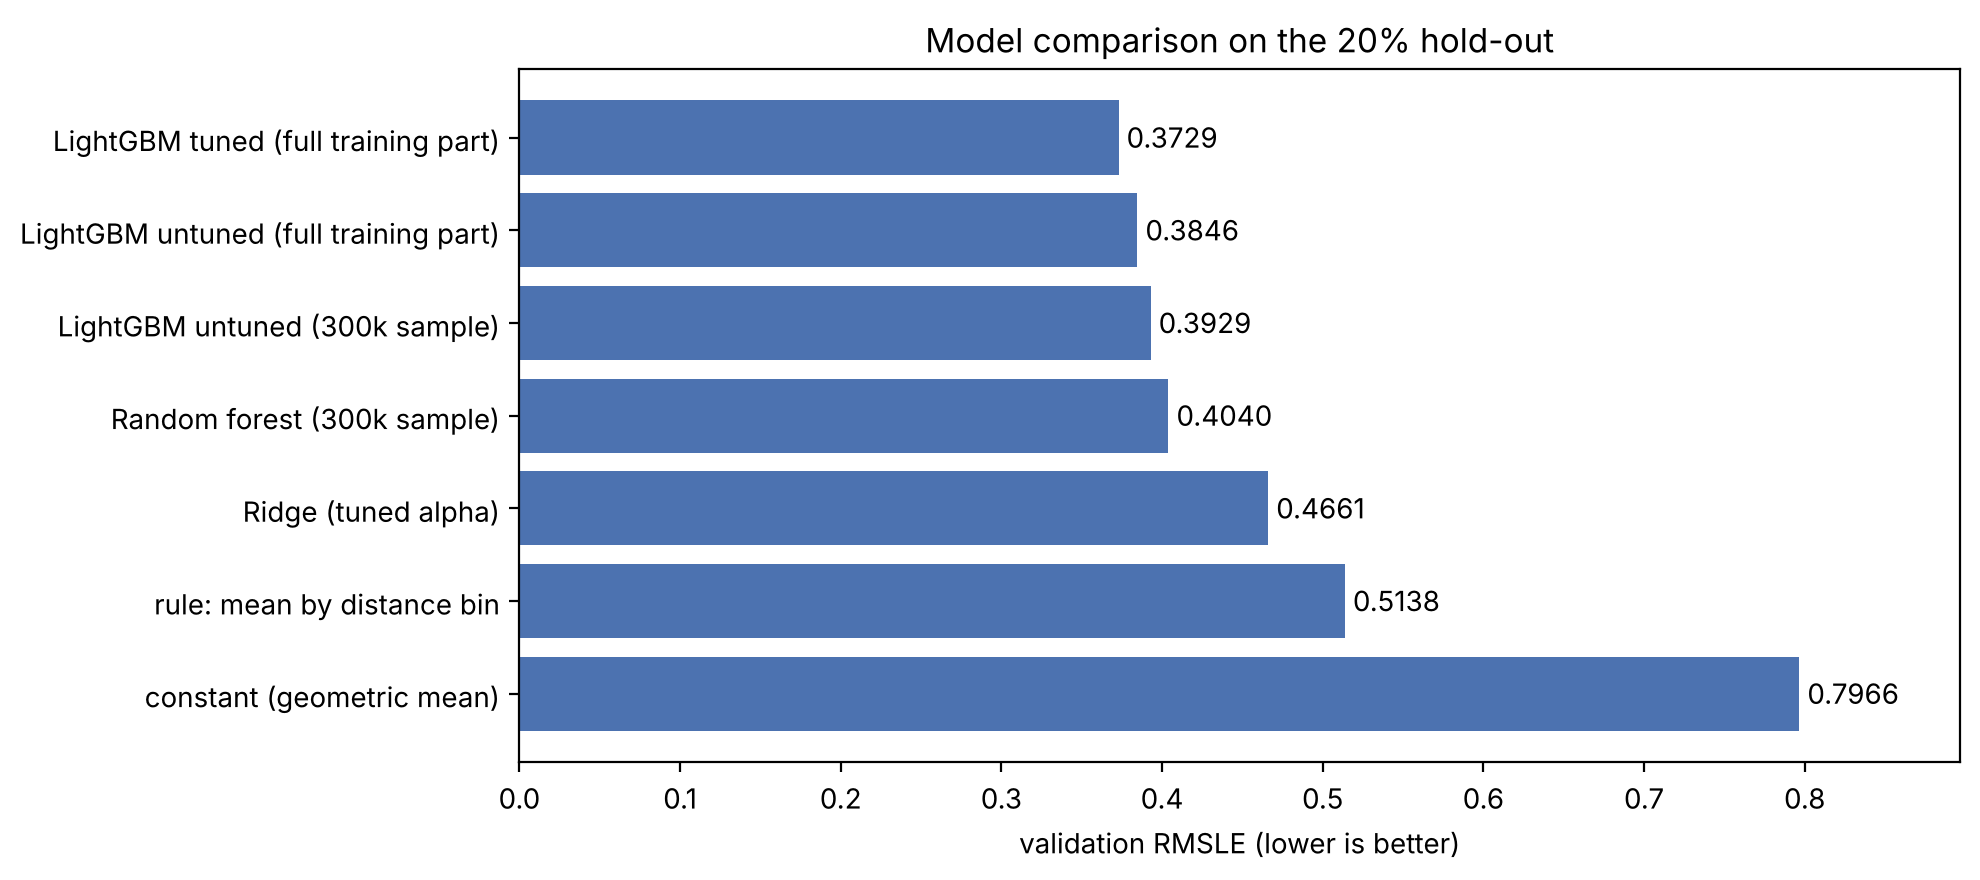

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(results["model"], results["valid RMSLE"], color="#4C72B0")
for i, v in enumerate(results["valid RMSLE"]):
    ax.text(v + 0.005, i, f"{v:.4f}", va="center")
ax.set(xlabel="validation RMSLE (lower is better)", title="Model comparison on the 20% hold-out",
       xlim=(0, results["valid RMSLE"].max() + 0.1))
fig.tight_layout()
fig.savefig(FIG_DIR / "03_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Final model and submission
**Choice:** tuned LightGBM — the best validation score by a wide margin, it handles the non-linear
time × location interactions without manual encoding, and trains on all 1.46M rows in minutes.
It is re-fitted on the **whole cleaned train set** with the number of trees found by early stopping,
scaled up by 10% because the full set is ~1.4× larger than the early-stopping fit part.

In [14]:
if "tuned_params" not in globals():   # session was reset: load the parameters saved by section 3
    import json
    saved = json.loads((ROOT / "reports" / "tuned_lightgbm.json").read_text())
    tuned_params, best_iter = saved["params"], saved["best_iter"]
    print("loaded tuned parameters from reports/tuned_lightgbm.json")

full = clean_train(train)
final = lgb_pipeline(params={**tuned_params, "n_estimators": int(best_iter * 1.1)})
t = time.time()
final.fit(full, np.log1p(full[TARGET]))
print(f"final fit: {time.time() - t:.0f}s")
sub = pd.DataFrame({"id": test["id"], TARGET: np.expm1(final.predict(test)).clip(1, None)})
path = SUB_DIR / "03_lightgbm_tuned.csv"
sub.to_csv(path, index=False)
print(path, sub.shape)
sub[TARGET].describe().round(1)

final fit: 311s


/home/claude/nyc-taxi-trip-duration/submissions/03_lightgbm_tuned.csv (625134, 2)


count    625134.0
mean        806.6
std         591.3
min           3.3
25%         402.0
50%         649.7
75%        1032.6
max        6136.1
Name: trip_duration, dtype: float64

## 6. Validation vs leaderboard
Both files were submitted as late submissions on 7 November 2026:

| submission | validation RMSLE | public LB (~30% of test) | private LB (~70% of test) |
|---|---|---|---|
| `02_lightgbm_untuned.csv` | 0.3846 | 0.39008 | 0.38762 |
| `03_lightgbm_tuned.csv` | 0.3729 | 0.37713 | **0.37512** |

**Discussion.**
* The leaderboard scores are only 0.002–0.005 worse than validation. The random 80/20 hold-out is a good
  imitation of the test set, as expected from the EDA (same period, random split).
* The improvement from tuning is the same on validation (−0.0117) and on the private LB (−0.0125), so the
  validation scheme ranks models correctly and the tuning did not over-fit the CV folds.
* The small remaining gap is plausible: the test set may contain a slightly larger share of the unpredictable
  anomalies (24 h trips, zero-distance rides), which dominate the error (Part 2). The public LB is computed on a
  smaller sample (~190k rows), so it is noisier than the private LB.